# 06 · Portfolios: holding many assets in chosen amounts

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/06_portfolios.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

So far every strategy held **one** asset, fully in or fully out. Real portfolios hold many assets in chosen amounts. This notebook builds a portfolio backtest with **weights**, tests two classic portfolio strategies against a fair benchmark, and shows one simple way to control risk. In notebook 07 you will put risk rules around a portfolio.

**What you'll do (~60 min):**
1. Backtest a portfolio of several assets with **weights**
2. **Sector rotation**: hold the strongest three of nine funds
3. Check the **most recent stretch** on its own
4. **Dual momentum**: the best asset, or cash
5. **Volatility targeting**: control the risk, not the return

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/aurvyl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. From one asset to a portfolio: weights

A **weight** is the share of your money in each asset: `0.25` means a quarter. Weights on a day add up to at most 1, and whatever is left sits in **cash**.

`run_portfolio_backtest(closes, weights)` follows the same rules as `run_backtest`:
- weights decided at a day's close are held **from the next day** (no look-ahead);
- every change of weight pays a trading cost on the size of the change (**turnover**);
- between trades the holdings **drift** with prices, like a real portfolio.

We start with the nine original US **sector funds**: each holds the big companies of one part of the economy (XLK technology, XLE energy, XLU utilities, ...).

In [2]:
from backtester import load_closes
from backtester.portfolio import run_portfolio_backtest, top_n_weights, month_ends, volatility_target
from backtester.metrics import recent_period

SECTORS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
closes = load_closes(SECTORS).dropna()
closes.tail()

,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
Date,,,,,,,,,
2026-10-05,49.50,63.45,53.88,170.10,200.93,81.04,39.97,167.37,110.42
2026-10-06,49.73,63.75,54.01,171.58,202.00,81.80,41.16,167.09,111.72
2026-10-07,48.98,63.36,53.75,167.84,201.39,81.70,41.15,168.81,111.36
2026-10-08,49.27,65.24,54.23,168.40,197.78,83.42,41.07,168.16,111.71
2026-10-09,49.43,65.08,54.73,169.25,198.78,83.43,41.41,170.81,112.85


## 2. Sector rotation: hold the strongest three

**Momentum** says assets that rose recently tend to keep rising for a while. A **sector rotation** strategy ranks the sectors by their last six months (126 trading days) of return, holds the **top three in equal parts**, and re-ranks on the **last trading day of each month**.

This is a **cross-sectional** strategy: it compares assets with each other, instead of comparing one asset with its own past. Much of real quant equity research looks like this.

In [3]:
momentum = closes / closes.shift(126) - 1
rotation_weights = top_n_weights(momentum, n=3, on=month_ends(closes.index))
rotation = run_portfolio_backtest(closes, rotation_weights, cost_bps=5, cash_rate=0.03)

print("Held at the end:", rotation_weights.iloc[-1][rotation_weights.iloc[-1] > 0].round(2).to_dict())
rotation.summary()

Held at the end: {'XLE': 0.33, 'XLK': 0.33, 'XLV': 0.33}


,Portfolio,Equal-weight buy & hold
Total return,226.0%,291.6%
Annual return (CAGR),11.6%,13.5%
Annual volatility,17.3%,17.0%
Sharpe ratio,0.55,0.66
Max drawdown,-31.4%,-35.7%


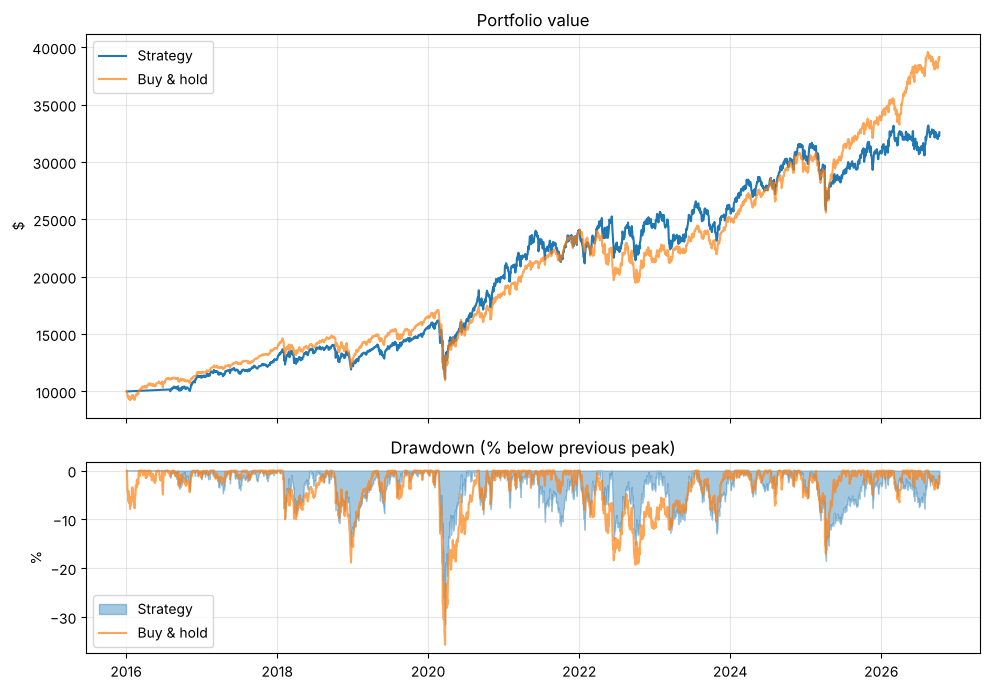

In [4]:
rotation.plot()

The benchmark is the fair comparison: **equal parts of all nine sectors, bought on day one and held**.

### Did it still work recently?

A strategy that only looks good over the whole history, and not over its **most recent stretch**, deserves suspicion. `recent_period` scores the **last 20%** of the backtest again, on its own.

In [5]:
recent_period(rotation, risk_free_rate=0.03)

From 2024-08-13,Strategy,Benchmark
Total return,15.8%,41.7%
Annual return (CAGR),7.1%,17.6%
Sharpe ratio,0.33,1.00
Max drawdown,-18.5%,-16.9%


**What the saved run shows.** Sector rotation grew money by 226% over the whole history. Simply holding all nine sectors grew it by 292%. The Sharpe ratio was 0.55 against 0.66. The rotation did have a slightly smaller worst fall (-31% against -36%), but that is a small prize for the lower return.

The last-20% check is harsher: from August 2024 the rotation made 16% while the benchmark made 42%. A famous idea can still lose to a plain benchmark on a given set of data. That is a result worth knowing before any money is involved.

## 3. Dual momentum: the best asset, or cash

**Dual momentum** mixes two ideas:
- **relative** momentum: of a few very different assets (US stocks, tech, small companies, long and medium government bonds, gold), hold the one with the best past year;
- **absolute** momentum: but only while its past year is **above zero**. Otherwise sit in cash.

Cash really did pay interest for much of this period, so this time we let cash earn **3% a year** (`cash_rate=0.03`). Sharpe is then measured *above* that rate, which is the honest way to do it.

In [6]:
ASSETS = ["SPY", "QQQ", "IWM", "TLT", "IEF", "GLD"]
assets = load_closes(ASSETS).dropna()
year_return = assets / assets.shift(252) - 1

best_one = top_n_weights(year_return, n=1, on=month_ends(assets.index))
dual_weights = best_one.where(year_return > 0, 0.0).where(month_ends(assets.index)).ffill().fillna(0.0)

dual = run_portfolio_backtest(assets, dual_weights, cost_bps=5, cash_rate=0.03, benchmark="SPY")
dual.summary()

,Portfolio,SPY buy & hold
Total return,219.3%,360.6%
Annual return (CAGR),11.4%,15.3%
Annual volatility,18.5%,17.7%
Sharpe ratio,0.52,0.73
Max drawdown,-29.6%,-33.7%


In [7]:
held = dual_weights.idxmax(axis=1).where(dual_weights.sum(axis=1) > 0, "cash")
held.loc["2021":"2023"].resample("QE").last().to_frame("held at quarter end")

,held at quarter end
Date,
2021-03-31,IWM
2021-06-30,IWM
2021-09-30,IWM
2021-12-31,SPY
2022-03-31,SPY
2022-06-30,GLD
2022-09-30,cash
2022-12-31,cash
2023-03-31,GLD


Look at 2022: stocks **and** bonds fell together. Dual momentum's absolute rule moved it to cash or gold. That is the whole point of the second rule.

**What the saved run shows.** Dual momentum made 219% against 361% for simply holding SPY (the US stock market fund), with a Sharpe ratio of 0.52 against 0.73. Its worst fall was a little smaller (-30% against -34%).

The absolute rule did what it was built for in 2022: it moved to gold and then cash while stocks and bonds fell together. But sitting out costs growth in the years when stocks keep rising, and over this history that cost was bigger than the protection it bought.

## 4. Volatility targeting: control the risk, not the return

A simple, widely used risk rule: if the portfolio has been bumpy lately, **hold less of it**.

`exposure = min(1, target volatility / recent volatility)`

With a 10% target, a portfolio swinging at 20% a year is held at half size; a calm one stays fully invested. It never borrows to go above 1.

In [8]:
calmer = volatility_target(rotation_weights, closes, target=0.10)
rotation_vt = run_portfolio_backtest(closes, calmer, cost_bps=5, cash_rate=0.03)

pd.DataFrame({
    "Sector rotation": rotation.summary()["Portfolio"],
    "Same, volatility targeted": rotation_vt.summary()["Portfolio"],
})

,Sector rotation,"Same, volatility targeted"
Total return,226.0%,118.3%
Annual return (CAGR),11.6%,7.5%
Annual volatility,17.3%,10.2%
Sharpe ratio,0.55,0.47
Max drawdown,-31.4%,-12.9%


**What the saved run shows.** Volatility targeting did exactly what its name says. Yearly volatility fell from 17.3% to 10.2%, and the worst fall from -31% to -13%. The price was growth: the yearly return fell from 11.6% to 7.5%, and the Sharpe ratio did not improve (0.55 to 0.47).

So the rule controls risk, not return. Whether that is a good trade depends on how much of a fall the investor can bear, which is the question of notebook 03.

## 5. ✏️ Your turn

- Change `n=3` to `n=2` or `n=5` in the sector rotation, or the 126-day lookback to 63 or 252. Does the rotation get closer to the benchmark, or further?
- Add `"XLC"`-style funds? Not in the data: use `available_tickers()` to see what is.
- Change the volatility `target` from 0.10 to 0.15. What happens to the return and the fall?

**Questions to discuss:**
- Rotation and dual momentum are famous, well-researched strategies. Why might they lose to a simple benchmark in this data?
- You checked the last 20% of the rotation. Would you have been happy to find that out after investing real money?
- Was the benchmark fair? What other benchmark would you pick?

> Educational use only. Simulated results on historical data; not financial advice.

### Next: risk rules for a portfolio

Limits, warning lines and four ways to react to a crash, on a portfolio of five tech funds.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aurvyl/qm-fintech-quant-workshop/blob/main/notebooks/07_portfolio_risk_rules.ipynb) `07_portfolio_risk_rules.ipynb`